# 💻 Nærmeste nabo-analyse

Når vi analyserer romlige data, er det ofte ikke bare interessant å vite *om* to geometrier overlapper eller ligger innenfor hverandre (som vi så med `sjoin()` og `overlay()`), men også **hvor nærme** de er hverandre, selv om de ikke overlapper. Dette kalles en *nærmeste nabo-analyse* (engelsk: *nearest neighbour analysis*), og brukes mye i praktisk GIS-arbeid, for eksempel for å finne:

- den nærmeste bussholdeplassen fra en adresse
- det nærmeste sykehuset fra et ulykkessted
- hvilke boliger som ligger lengst fra en tjeneste (tilgjengelighetsanalyse)

I denne notebooken (inspirert av [kapittel 6.7 i Python for Geographic Data Analysis](https://python-gis-book.readthedocs.io/en/latest/part2/chapter-06/nb/07-nearest-neighbour.html)) skal vi finne det **nærmeste kjøpesenteret** for hver adresse i adressedatasettet vi har brukt tidligere i kurset.


In [1]:
import pathlib 
NOTEBOOK_PATH = pathlib.Path().resolve()
DATA_MAPPE = NOTEBOOK_PATH / "data"

## Last inn inngangsdata

Vi bruker to datasett:

1. `adresser`, adressepunktene fra Oslo som vi har brukt i tidligere forelesninger
2. `kjopesentre`, buffere rundt kjøpesentre i Oslo som vi har brukt tidligere

In [ ]:
import geopandas

adresser = geopandas.read_file(DATA_MAPPE / "oslo_adresser" / "adresser.geojson")
kjopesentre = geopandas.read_file(DATA_MAPPE / "oslo_adresser" / "shopping_centres.geojson")

kjopesentre.head()

,id,navn,adr,geometry
0,1,Oslo City,"1D, Stenersgata, Vaterland, Sentrum, Oslo, 005...","POLYGON ((599522.028 6643021.947, 599514.805 6..."
1,2,Bryn Senter,"Østensjøveien 79, 0667 Oslo","POLYGON ((603440.781 6642032.843, 603433.558 6..."
2,3,Storo Storsenter,"Vitaminveien 7, 0485 Oslo","POLYGON ((600677.887 6646821.293, 600670.664 6..."
3,4,Lambertseter senter,"Cecilie Thoresens vei 17, 1153 Oslo","POLYGON ((602855.975 6638866.012, 602848.752 6..."
4,5,Manglerud Senter,"Plogveien 6, 0679 Oslo","POLYGON ((602921.991 6641360.986, 602914.769 6..."


Som vi ser er `kjopesentre` polygoner, med kolonnene `navn` og `adr` i tillegg til `geometry`. `sjoin_nearest()`, som vi skal bruke senere i denne notebooken, fungerer uavhengig av hvilken geometritype vi har (punkt, linje eller polygon) — men polygonene her er egentlig buffere vi har lagd tidligere for hvert kjøpesenter. For denne analysen er vi egentlig bare interessert i *hvor* hvert kjøpesenter ligger, ikke i bufferen. La oss derfor, som vi gjorde med `.centroid` i en tidligere forelesning, representere hvert kjøpesenter med et enkelt punkt i stedet for en polygon:

In [3]:
kjopesentre["geometry"] = kjopesentre.centroid
kjopesentre.head()

,id,navn,adr,geometry
0,1,Oslo City,"1D, Stenersgata, Vaterland, Sentrum, Oslo, 005...",POINT (598022.028 6643021.947)
1,2,Bryn Senter,"Østensjøveien 79, 0667 Oslo",POINT (601940.781 6642032.843)
2,3,Storo Storsenter,"Vitaminveien 7, 0485 Oslo",POINT (599177.887 6646821.293)
3,4,Lambertseter senter,"Cecilie Thoresens vei 17, 1153 Oslo",POINT (601355.975 6638866.012)
4,5,Manglerud Senter,"Plogveien 6, 0679 Oslo",POINT (601421.991 6641360.986)


## Sjekke og tilpasse koordinatsystem

Siden vi skal regne ut faktiske avstander, må dataene våre være i et projisert koordinatsystem med en metrisk enhet (meter), og begge lagene må dele samme CRS. La oss sjekke:

In [4]:
print(adresser.crs)
print(kjopesentre.crs)

EPSG:4326
EPSG:25832


`adresser` er i `EPSG:4326` (lengde-/breddegrader), mens `kjopesentre` allerede er i `EPSG:25832`, et projisert koordinatsystem med meter som enhet som passer godt for norske data. La oss reprojisere `adresser` til samme CRS:

In [5]:
adresser = adresser.to_crs(kjopesentre.crs)
assert adresser.crs == kjopesentre.crs, "CRS er ikke identiske"

## Konseptet: `shapely.ops.nearest_points()`

Før vi bruker det praktiske verktøyet i geopandas, er det nyttig å se selve ideen bak en nærmeste nabo-analyse på to enkeltgeometrier med `shapely`. Funksjonen [`nearest_points()`](https://shapely.readthedocs.io/en/stable/manual.html#nearest-points) tar inn to geometrier, og returnerer et par med de to punktene (ett fra hver geometri) som ligger nærmest hverandre.

La oss prøve dette med den første adressen i datasettet, mot *alle* kjøpesentrene samlet som én geometri (ved hjelp av `union_all()`, som vi har brukt tidligere):

In [6]:
import shapely.ops

en_adresse = adresser.iloc[0].geometry
naermeste_punkter = shapely.ops.nearest_points(en_adresse, kjopesentre.union_all())
naermeste_punkter

(<POINT (602608.017 6646267.986)>, <POINT (602545.007 6646512.039)>)

`nearest_points()` gir oss tilbake selve punktene, men ikke noe mer informasjon: vi får ikke vite *hvilket* kjøpesenter (hvilken rad) som var nærmest, og heller ikke *hvor langt* unna det er. For å finne det, må vi regne ut avstanden selv med `.distance()`, og vi måtte i tillegg iterere over alle radene i `adresser` for å gjøre dette for hver adresse enkeltvis — det ville fungert, men ville vært tungvint og ville tatt mye lenger tid å kjøre for et stort datasett.

Derfor har geopandas et eget verktøy som gjør akkurat denne jobben for oss, mye raskere og med én kommando.

## Nærmeste nabo-kobling med `sjoin_nearest()`

Metoden [`sjoin_nearest()`](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.sjoin_nearest.html) fungerer på samme måte som `sjoin()` som vi brukte i en tidligere forelesning, men i stedet for å koble sammen rader basert på et romlig predikat (som `within`), kobler den hver rad i venstre GeoDataFrame til den *nærmeste* raden i høyre GeoDataFrame — uavhengig av om de overlapper eller ikke.

Med parameteren `distance_col` kan vi også få avstanden til det nærmeste objektet lagt til som en egen kolonne:

In [7]:
adresser_med_naermeste = adresser.sjoin_nearest(
    kjopesentre,
    distance_col="avstand_meter"
)
adresser_med_naermeste.head()

,fid,address,id_left,adr_left,geometry,index_right,id_right,navn,adr_right,avstand_meter
0,1,"25, Statsråd Mathiesens vei, Linderud, Bjerke,...",100,"Statsråd Mathiesens vei 25, 0594 OSLO",POINT (602608.017 6646267.986),5,6,Linderud senter,"Erich Mogensøns vei 38, 0594 Oslo",252.055955
1,2,"15, Slimeveien, Bjørnholt, Søndre Nordstrand, ...",101,"Slimeveien 15, 1275 OSLO",POINT (602813.008 6634521.994),3,4,Lambertseter senter,"Cecilie Thoresens vei 17, 1153 Oslo",4581.859492
2,3,"Sognsveien 80, Konvallveien, Sogn, Nordre Aker...",102,"Sognsveien 80, 0855 OSLO",POINT (596608.772 6647117.829),2,3,Storo Storsenter,"Vitaminveien 7, 0485 Oslo",2586.172330
3,4,"5, Ullevålsveien, Hammersborg, St. Hanshaugen,...",103,"Ullevålsveien 5, 0165 OSLO",POINT (597483.025 6643632.991),0,1,Oslo City,"1D, Stenersgata, Vaterland, Sentrum, Oslo, 005...",814.799803
4,5,"30B, Nydalsveien, Nydalen, Nordre Aker, Oslo, ...",104,"Nydalsveien 30b, 0484 OSLO",POINT (598533.021 6647189.003),2,3,Storo Storsenter,"Vitaminveien 7, 0485 Oslo",742.336376


Som med `sjoin()` har vi nå attributtene fra begge lagene i resultatet, og i tillegg en kolonne `avstand_meter` som viser avstanden (i meter, siden CRS-en vår bruker meter som enhet) til det nærmeste kjøpesenteret for hver adresse.

La oss finne adressen som ligger *lengst* unna sitt nærmeste kjøpesenter:

In [8]:
adresser_med_naermeste.sort_values("avstand_meter", ascending=False).head()

,fid,address,id_left,adr_left,geometry,index_right,id_right,navn,adr_right,avstand_meter
22,23,"1, Gamle Hovsetervei, Nordre Huseby, Vestre Ak...",122,"Gamle Hovsetervei 1, 0768 OSLO",POINT (592618.008 6646485.004),0,1,Oslo City,"1D, Stenersgata, Vaterland, Sentrum, Oslo, 005...",6418.426529
23,24,"25, Karl Fossums vei, Fossum, Stovner, Oslo, 0...",123,"Karl Fossums vei 25, 0913 OSLO",POINT (607589.004 6648579.001),5,6,Linderud senter,"Erich Mogensøns vei 38, 0594 Oslo",5451.076468
25,26,"66, Ullernchausséen, Montebello, Ullern, Oslo,...",125,"Ullernchaussèen 66, 0379 OSLO",POINT (592969.589 6644909.861),0,1,Oslo City,"1D, Stenersgata, Vaterland, Sentrum, Oslo, 005...",5393.641048
1,2,"15, Slimeveien, Bjørnholt, Søndre Nordstrand, ...",101,"Slimeveien 15, 1275 OSLO",POINT (602813.008 6634521.994),3,4,Lambertseter senter,"Cecilie Thoresens vei 17, 1153 Oslo",4581.859492
18,19,"67, Sognsvannsveien, Rabben, Nordre Aker, Oslo...",118,"Sognsvannsveien 67, 0372 OSLO",POINT (595915.988 6647877.02),2,3,Storo Storsenter,"Vitaminveien 7, 0485 Oslo",3428.490321


:::{admonition} Sjekk din forståelse
:class: hint

Se på adressen med lengst `avstand_meter` ovenfor. Hvilken bydel tror du den ligger i, og gir det mening at den ligger langt fra et kjøpesenter? Du kan sjekke dette selv ved å gjøre en romlig kobling (`sjoin()`) mellom denne adressen og bydelslaget fra en tidligere forelesning.
:::

## Visualisere resultatet

La oss plotte adressene, farget etter hvor langt de er fra sitt nærmeste kjøpesenter, sammen med kjøpesentrene selv:

Text(0.5, 1.0, 'Avstand (meter) til nærmeste kjøpesenter')

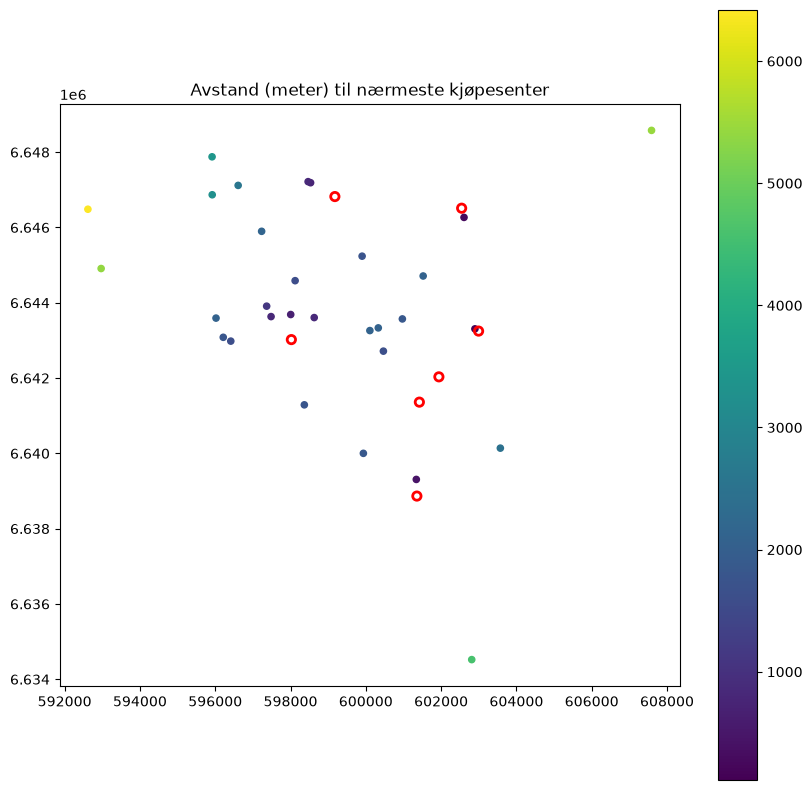

In [9]:
ax = adresser_med_naermeste.plot(
    figsize=(10, 10),
    column="avstand_meter",
    cmap="viridis",
    markersize=20,
    legend=True
)
kjopesentre.plot(ax=ax, facecolor="none", edgecolor="red", linewidth=2)
ax.set_title("Avstand (meter) til nærmeste kjøpesenter")

## Avgrense søket med `max_distance`

Noen ganger er vi bare interessert i objekter som faktisk har *noe* innen en gitt avstand, ikke bare det nærmeste uansett hvor langt unna det er. `sjoin_nearest()` har derfor en `max_distance`-parameter: hvis ingen rad i høyre GeoDataFrame er innenfor denne avstanden, får raden `NaN`-verdier i stedet (så lenge vi bruker `how="left"`, som beholder alle adressene uavhengig av treff).

La oss finne ut hvor mange adresser som *ikke* har et kjøpesenter innen 1000 meter:

In [10]:
adresser_naer_senter = adresser.sjoin_nearest(
    kjopesentre,
    how="left",
    distance_col="avstand_meter",
    max_distance=1000
)

antall_uten_senter_i_naerheten = adresser_naer_senter["avstand_meter"].isna().sum()
antall_uten_senter_i_naerheten

np.int64(22)

Det er mange flere bruksområder for nærmeste nabo-analyser i [geopandas sin egen dokumentasjon](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.sjoin_nearest.html), og i [Python for Geographic Data Analysis, kapittel 6.7](https://python-gis-book.readthedocs.io/en/latest/part2/chapter-06/nb/07-nearest-neighbour.html), som blant annet også viser hvordan man kan finne *flere* nærmeste naboer (ikke bare den aller nærmeste) ved hjelp av biblioteket `scikit-learn`.